<a href="https://colab.research.google.com/github/Shihabalfaj6062/aiml-lab-problem-1-/blob/main/Stroke_SMOTE_Tuned_Comparison_2_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction: Class Imbalance Handling with SMOTE

**Objective:** Compare six classifiers before and after SMOTE using the same stratified train/test split. The primary evaluation metrics are **Stroke-class Recall and F1-score**, while Accuracy, Precision and ROC-AUC are also reported.

> Important: SMOTE does not guarantee that every metric or every algorithm improves. It often increases minority-class recall while reducing accuracy or precision because the model detects more stroke cases but may also produce more false positives. The notebook tunes models using training data only and keeps the test set untouched.

In [1]:
!pip -q install -U imbalanced-learn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# Upload the processed dataset
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())
print("\\nOriginal class distribution:")
print(df["stroke"].value_counts().sort_index())

# Confirm the target is present and contains the expected two classes
assert "stroke" in df.columns, "The dataset must contain a 'stroke' target column."
assert set(df["stroke"].dropna().unique()).issubset({0, 1}), "Target must be encoded as 0 and 1."
assert df.isnull().sum().sum() == 0, "Handle missing values before running this notebook."

X = df.drop(columns=["stroke"])
y = df["stroke"].astype(int)

print("\\nClass proportions:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2).astype(str) + "%")

Saving stroke_processed (3).csv to stroke_processed (3).csv
Dataset shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


\nOriginal class distribution:
stroke
0    4861
1     249
Name: count, dtype: int64
\nClass proportions:
stroke
0    95.13%
1     4.87%
Name: proportion, dtype: object


## 1. Train/test split

The test set is separated **before** SMOTE. SMOTE is applied only inside the training pipeline. This prevents synthetic samples from leaking into the test set.

Training samples: 4088
Testing samples: 1022
\nTraining distribution before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64


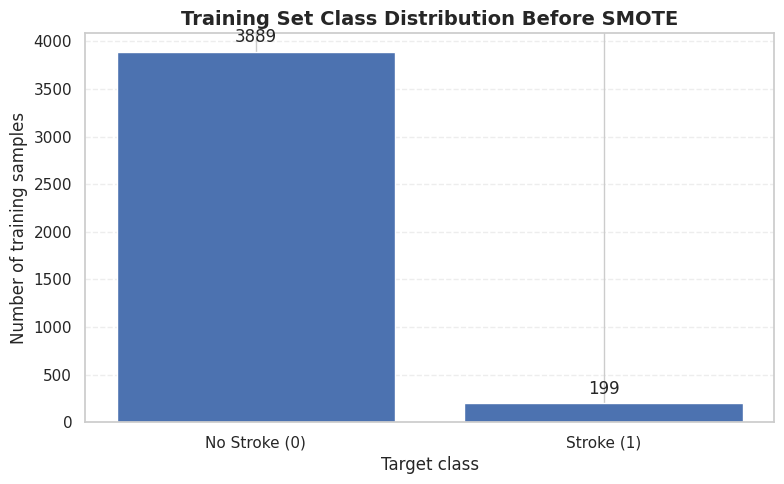

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\\nTraining distribution before SMOTE:")
print(y_train.value_counts().sort_index())

# Visualise the training distribution before resampling
before_counts = y_train.value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["No Stroke (0)", "Stroke (1)"], before_counts.values)
ax.bar_label(bars, padding=4)
ax.set_title("Training Set Class Distribution Before SMOTE", fontsize=14, weight="bold")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of training samples")
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## 2. Baseline models (without SMOTE)

All six baseline models use the same training and test partitions. Scaling is fitted only on training data. The baseline models are not trained on synthetic samples.

In [4]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "ANN": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                         early_stopping=True, random_state=RANDOM_STATE)
}

def calculate_metrics(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)

    return {
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1-Score": f1_score(y_eval, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC-ROC": roc_auc_score(y_eval, y_score),
        "Predictions": y_pred,
        "Confusion Matrix": confusion_matrix(y_eval, y_pred)
    }

baseline_results = []
baseline_fitted = {}
baseline_confusions = {}

for name, estimator in baseline_models.items():
    model = SklearnPipeline([
        ("scaler", StandardScaler()),
        ("classifier", estimator)
    ])
    model.fit(X_train, y_train)
    scores = calculate_metrics(model, X_test, y_test)
    baseline_fitted[name] = model
    baseline_confusions[name] = scores["Confusion Matrix"]
    baseline_results.append({"Model": name, **{k: scores[k] for k in
        ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]}})

baseline_df = pd.DataFrame(baseline_results)
print("Baseline performance on the untouched test set:")
display(baseline_df.round(4))

Baseline performance on the untouched test set:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.0,0.00,0.0000,0.9511,0.8377
1,Decision Tree,0.0,0.00,0.0000,0.9462,0.7917
2,Random Forest,0.0,0.00,0.0000,0.9481,0.8141
3,SVM,0.0,0.00,0.0000,0.9511,0.6108
4,KNN,0.2,0.02,0.0364,0.9481,0.6140
5,ANN,0.0,0.00,0.0000,0.9511,0.5410


## 3. Tune models with SMOTE

RandomizedSearchCV selects hyperparameters using **F1-score for the positive class (Stroke = 1)**. Each cross-validation fold performs scaling and SMOTE inside its own training partition. The test set is not used for tuning.

The search spaces are deliberately moderate so the notebook can run in Colab. You can increase `n_iter` for a more extensive search if time permits.

In [5]:
smote_models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, solver="liblinear", random_state=RANDOM_STATE),
        {
            "classifier__C": [0.01, 0.1, 1, 5, 10, 20],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "classifier__max_depth": [3, 5, 8, 12, None],
            "classifier__min_samples_leaf": [2, 5, 10, 20],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
        {
            "classifier__max_depth": [5, 8, 12, None],
            "classifier__min_samples_leaf": [2, 5, 10],
            "classifier__max_features": ["sqrt", 0.8],
            "classifier__class_weight": [None, "balanced_subsample"]
        }
    ),
    "SVM": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {
            "classifier__C": [0.1, 1, 5, 10],
            "classifier__gamma": ["scale", 0.01, 0.1],
            "classifier__kernel": ["rbf"]
        }
    ),
    "KNN": (
        KNeighborsClassifier(),
        {
            "classifier__n_neighbors": [3, 5, 7, 9, 11, 15],
            "classifier__weights": ["uniform", "distance"],
            "classifier__p": [1, 2]
        }
    ),
    "ANN": (
        MLPClassifier(max_iter=700, early_stopping=True, random_state=RANDOM_STATE),
        {
            "classifier__hidden_layer_sizes": [(32,), (64,), (64, 32), (100, 50)],
            "classifier__alpha": [0.0001, 0.001, 0.01],
            "classifier__learning_rate_init": [0.0005, 0.001]
        }
    )
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
smote_results = []
smote_fitted = {}
smote_confusions = {}
best_parameters = {}

for name, (estimator, parameter_space) in smote_models.items():
    print(f"\\nTuning {name} ...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ("classifier", estimator)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_space,
        n_iter=10,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=0
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    scores = calculate_metrics(best_model, X_test, y_test)

    smote_fitted[name] = best_model
    smote_confusions[name] = scores["Confusion Matrix"]
    best_parameters[name] = search.best_params_
    smote_results.append({
        "Model": name,
        "CV Best F1": search.best_score_,
        **{k: scores[k] for k in ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]}
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

smote_df = pd.DataFrame(smote_results)
print("\\nTuned SMOTE model performance on the untouched test set:")
display(smote_df.round(4))

\nTuning Logistic Regression ...
Best CV F1: 0.2298
Best parameters: {'classifier__class_weight': None, 'classifier__C': 20}
\nTuning Decision Tree ...
Best CV F1: 0.2042
Best parameters: {'classifier__min_samples_leaf': 20, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
\nTuning Random Forest ...
Best CV F1: 0.2137
Best parameters: {'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced_subsample'}
\nTuning SVM ...
Best CV F1: 0.2189
Best parameters: {'classifier__kernel': 'rbf', 'classifier__gamma': 0.01, 'classifier__C': 0.1}
\nTuning KNN ...
Best CV F1: 0.1672
Best parameters: {'classifier__weights': 'uniform', 'classifier__p': 2, 'classifier__n_neighbors': 11}
\nTuning ANN ...
Best CV F1: 0.2211
Best parameters: {'classifier__learning_rate_init': 0.001, 'classifier__hidden_layer_sizes': (32,), 'classifier__alpha': 0.0001}
\nTuned SMOTE model performance on the untouched test set:

,Model,CV Best F1,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.2298,0.1460,0.80,0.2469,0.7613,0.8381
1,Decision Tree,0.2042,0.1238,0.80,0.2145,0.7133,0.7609
2,Random Forest,0.2137,0.1314,0.82,0.2265,0.7260,0.8278
3,SVM,0.2189,0.1227,0.80,0.2128,0.7104,0.8398
4,KNN,0.1672,0.1107,0.54,0.1837,0.7652,0.7174
5,ANN,0.2211,0.1418,0.78,0.2400,0.7583,0.8365


## 4. Verify the class distribution after SMOTE

This plot is based on the training data only. The test set remains imbalanced because it represents the real-world distribution.

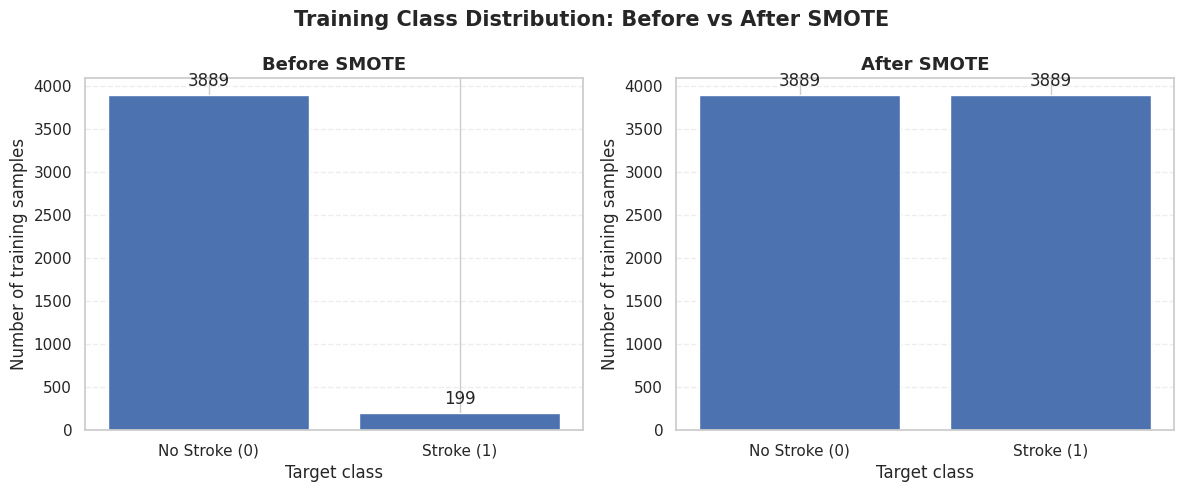

Before SMOTE: {0: 3889, 1: 199}
After SMOTE: {0: 3889, 1: 3889}


In [6]:
# Demonstrate the resampling counts separately for reporting/visualisation.
# The fitted model pipelines above also apply SMOTE within each CV training fold.
scaler_for_plot = StandardScaler()
X_train_scaled_for_plot = scaler_for_plot.fit_transform(X_train)
X_train_smote_plot, y_train_smote_plot = SMOTE(
    random_state=RANDOM_STATE, k_neighbors=5
).fit_resample(X_train_scaled_for_plot, y_train)

after_counts = pd.Series(y_train_smote_plot).value_counts().reindex([0, 1], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, counts, title in [
    (axes[0], before_counts, "Before SMOTE"),
    (axes[1], after_counts, "After SMOTE")
]:
    bars = ax.bar(["No Stroke (0)", "Stroke (1)"], counts.values)
    ax.bar_label(bars, padding=4)
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xlabel("Target class")
    ax.set_ylabel("Number of training samples")
    ax.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Training Class Distribution: Before vs After SMOTE", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

print("Before SMOTE:", before_counts.to_dict())
print("After SMOTE:", after_counts.to_dict())

## 5. Compare baseline and tuned SMOTE results

A decrease in Accuracy is not automatically a failure. Focus on whether Stroke-class Recall and F1-score improve, while checking Precision and false positives. All values below are measured on the same untouched test set.

In [7]:
comparison = baseline_df.merge(
    smote_df.drop(columns=["CV Best F1"]),
    on="Model",
    suffixes=("_Original", "_SMOTE")
)

metric_columns = ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]
display(comparison.round(4))

# Show absolute metric changes (SMOTE minus baseline)
for metric in metric_columns:
    comparison[f"{metric}_Change"] = (
        comparison[f"{metric}_SMOTE"] - comparison[f"{metric}_Original"]
    )

change_columns = ["Model"] + [f"{m}_Change" for m in metric_columns]
print("Metric change after tuned SMOTE (positive means an increase):")
display(comparison[change_columns].round(4))

,Model,Precision_Original,Recall_Original,F1-Score_Original,Accuracy_Original,AUC-ROC_Original,Precision_SMOTE,Recall_SMOTE,F1-Score_SMOTE,Accuracy_SMOTE,AUC-ROC_SMOTE
0,Logistic Regression,0.0,0.00,0.0000,0.9511,0.8377,0.1460,0.80,0.2469,0.7613,0.8381
1,Decision Tree,0.0,0.00,0.0000,0.9462,0.7917,0.1238,0.80,0.2145,0.7133,0.7609
2,Random Forest,0.0,0.00,0.0000,0.9481,0.8141,0.1314,0.82,0.2265,0.7260,0.8278
3,SVM,0.0,0.00,0.0000,0.9511,0.6108,0.1227,0.80,0.2128,0.7104,0.8398
4,KNN,0.2,0.02,0.0364,0.9481,0.6140,0.1107,0.54,0.1837,0.7652,0.7174
5,ANN,0.0,0.00,0.0000,0.9511,0.5410,0.1418,0.78,0.2400,0.7583,0.8365


Metric change after tuned SMOTE (positive means an increase):


,Model,Precision_Change,Recall_Change,F1-Score_Change,Accuracy_Change,AUC-ROC_Change
0,Logistic Regression,0.1460,0.80,0.2469,-0.1898,0.0004
1,Decision Tree,0.1238,0.80,0.2145,-0.2329,-0.0308
2,Random Forest,0.1314,0.82,0.2265,-0.2221,0.0138
3,SVM,0.1227,0.80,0.2128,-0.2407,0.2290
4,KNN,-0.0893,0.52,0.1473,-0.1830,0.1034
5,ANN,0.1418,0.78,0.2400,-0.1928,0.2955


## 6. Labelled performance comparison graphs

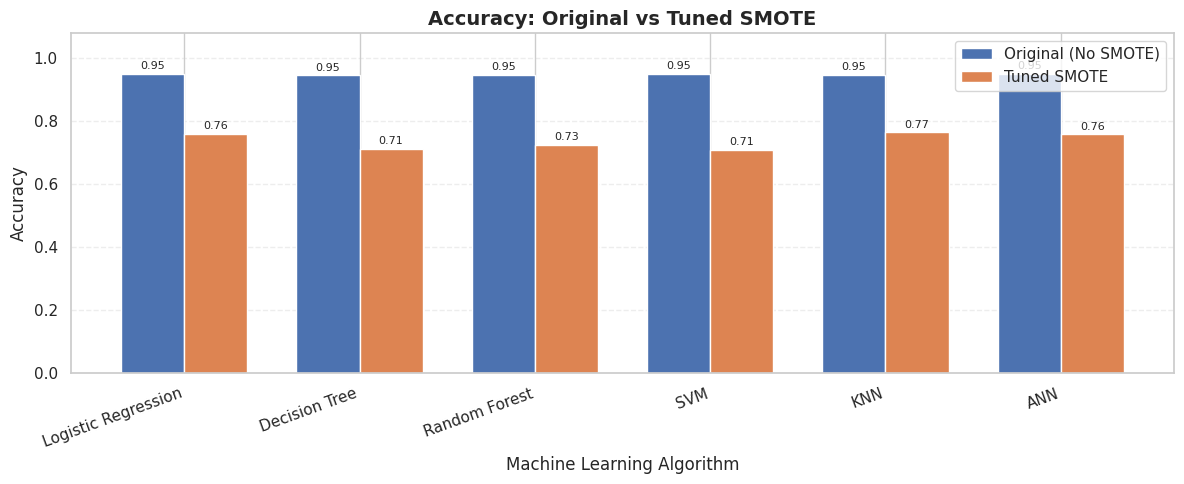

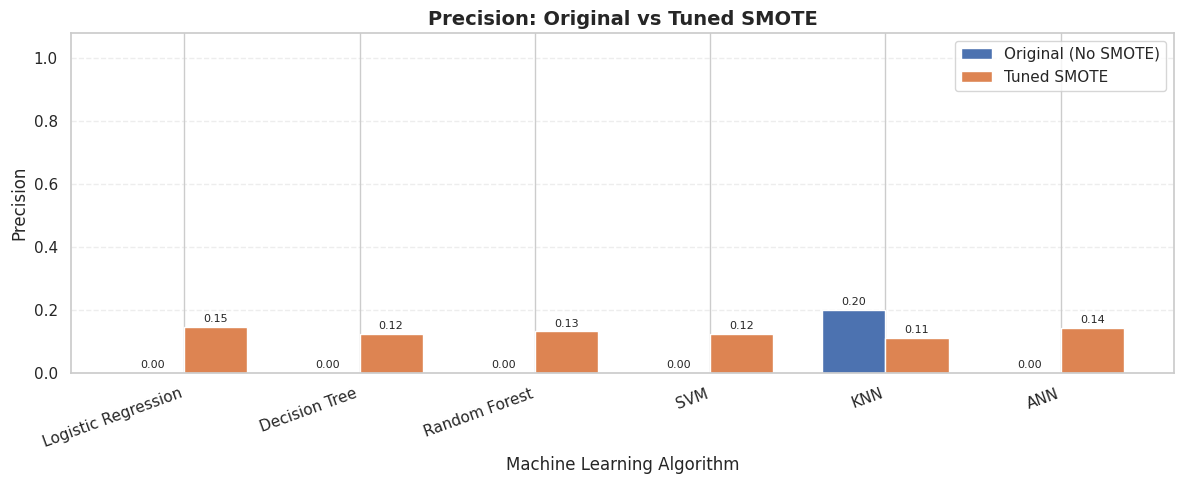

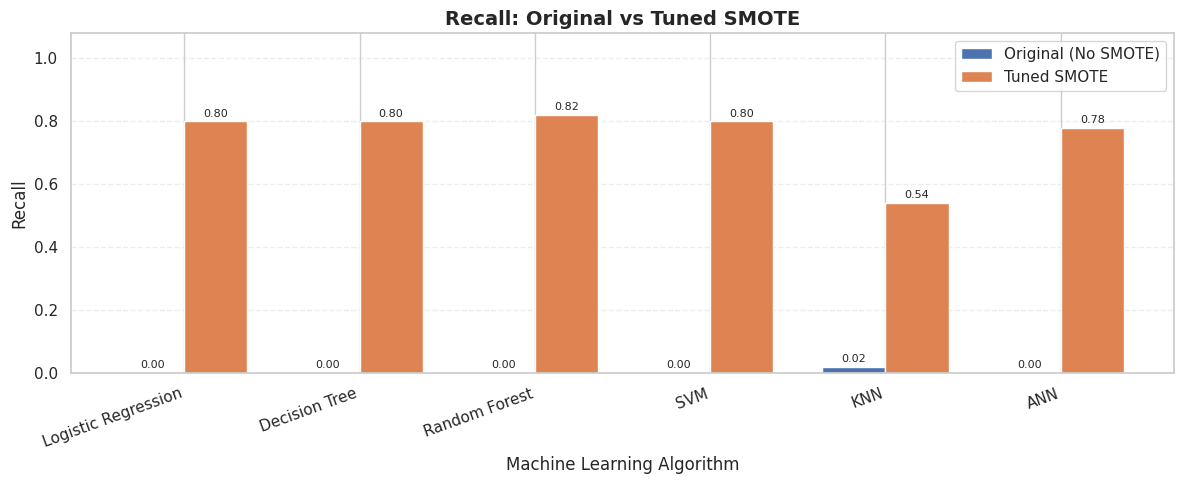

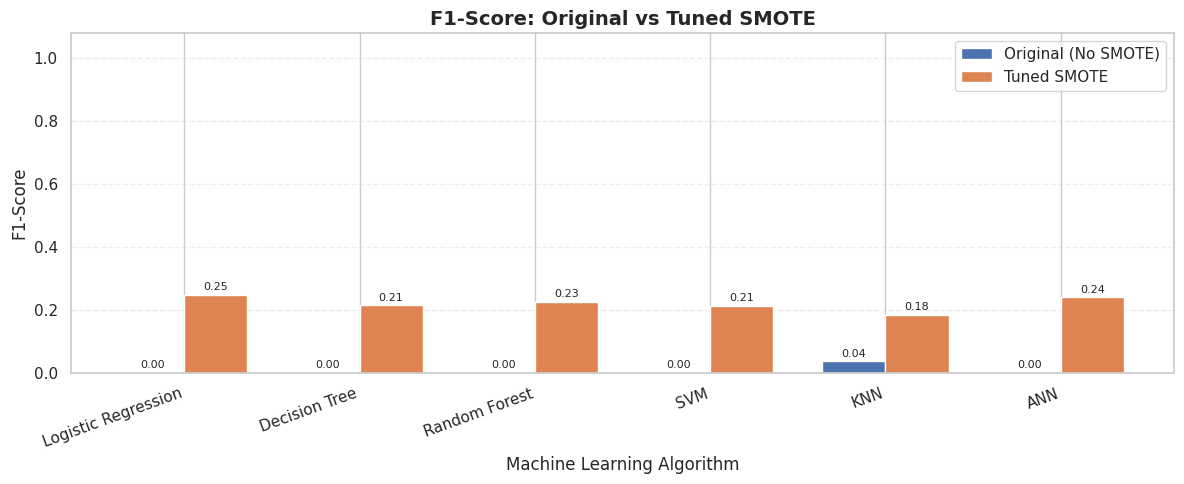

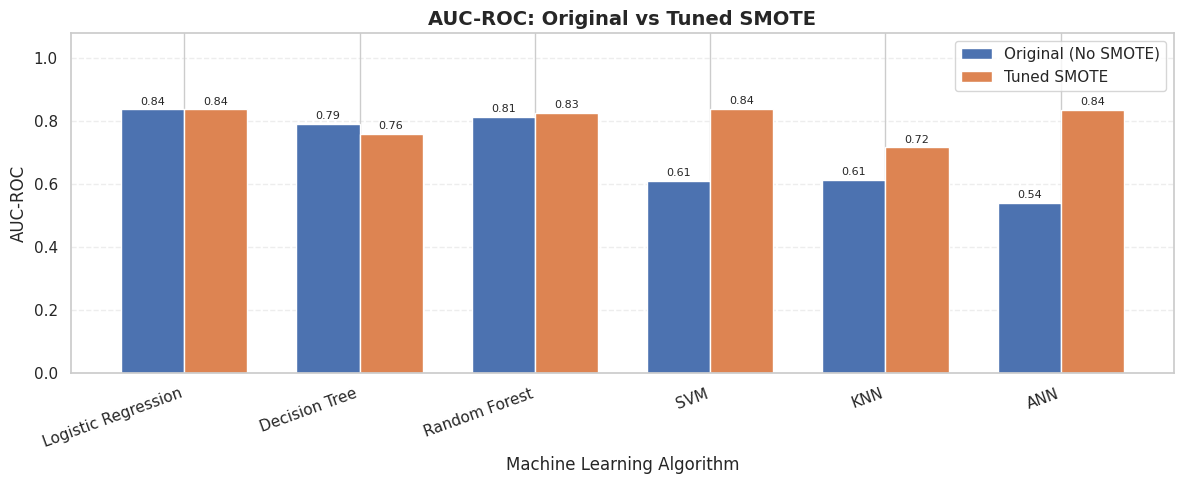

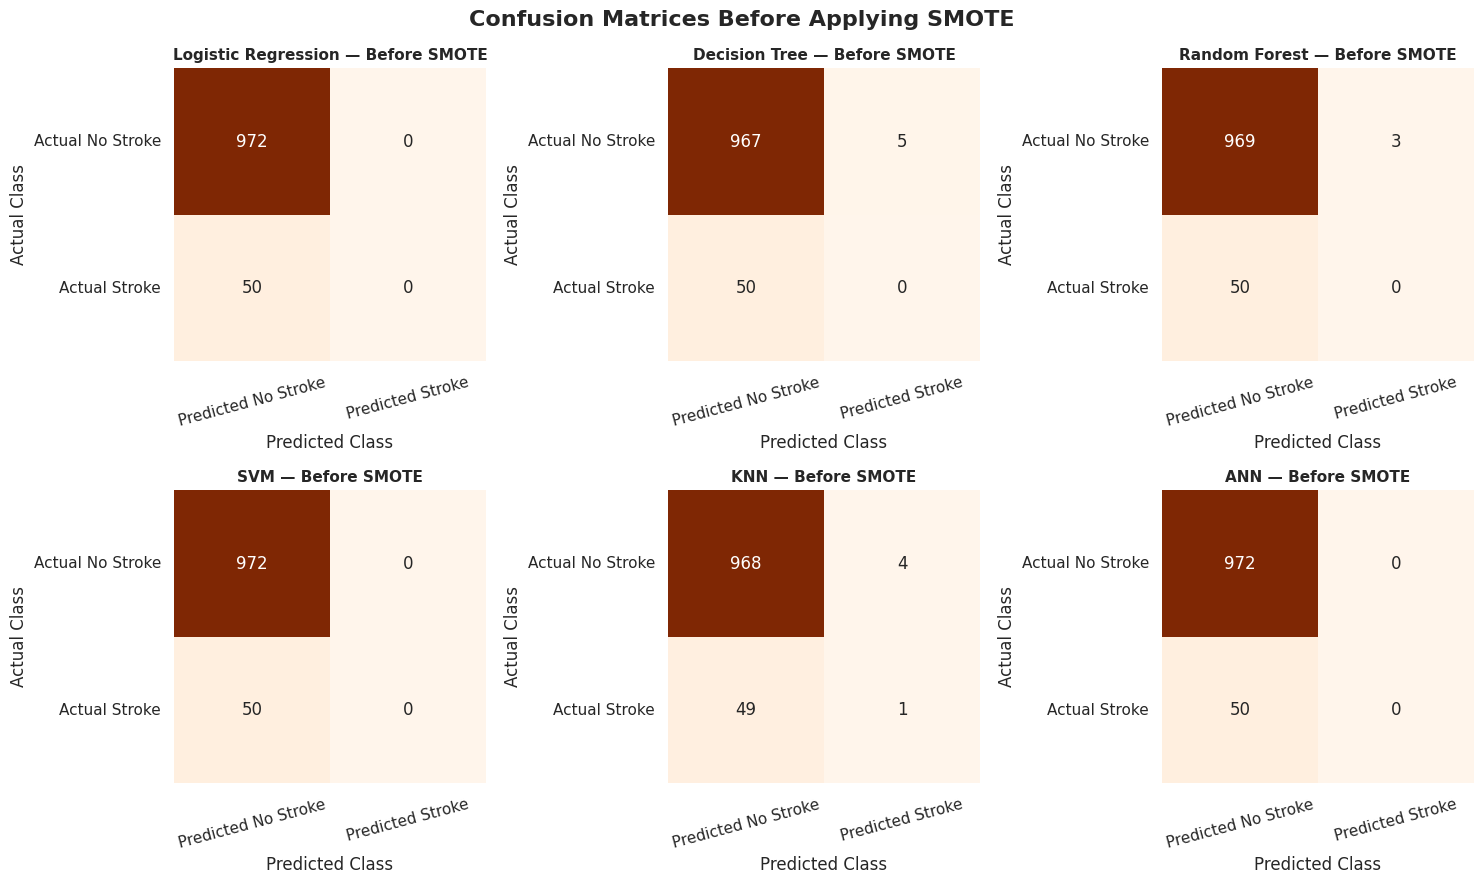

In [8]:
plot_metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]

for metric in plot_metrics:
    x = np.arange(len(comparison))
    width = 0.36

    fig, ax = plt.subplots(figsize=(12, 5))
    bars1 = ax.bar(x - width/2, comparison[f"{metric}_Original"], width,
                   label="Original (No SMOTE)")
    bars2 = ax.bar(x + width/2, comparison[f"{metric}_SMOTE"], width,
                   label="Tuned SMOTE")

    ax.set_title(f"{metric}: Original vs Tuned SMOTE", fontsize=14, weight="bold")
    ax.set_xlabel("Machine Learning Algorithm")
    ax.set_ylabel(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison["Model"], rotation=20, ha="right")
    ax.set_ylim(0, 1.08)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.bar_label(bars1, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(bars2, fmt="%.2f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()

    # Confusion Matrices Before Applying SMOTE

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, cm) in zip(axes.flatten(), baseline_confusions.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        ax=ax,
        xticklabels=["Predicted No Stroke", "Predicted Stroke"],
        yticklabels=["Actual No Stroke", "Actual Stroke"]
    )

    ax.set_title(f"{name} — Before SMOTE", fontsize=11, weight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.tick_params(axis="x", rotation=15)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "Confusion Matrices Before Applying SMOTE",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()

## 7. Confusion matrices for tuned SMOTE models

The confusion matrices show True Negatives, False Positives, False Negatives and True Positives. For stroke detection, False Negatives are particularly important because they represent stroke cases missed by the model.

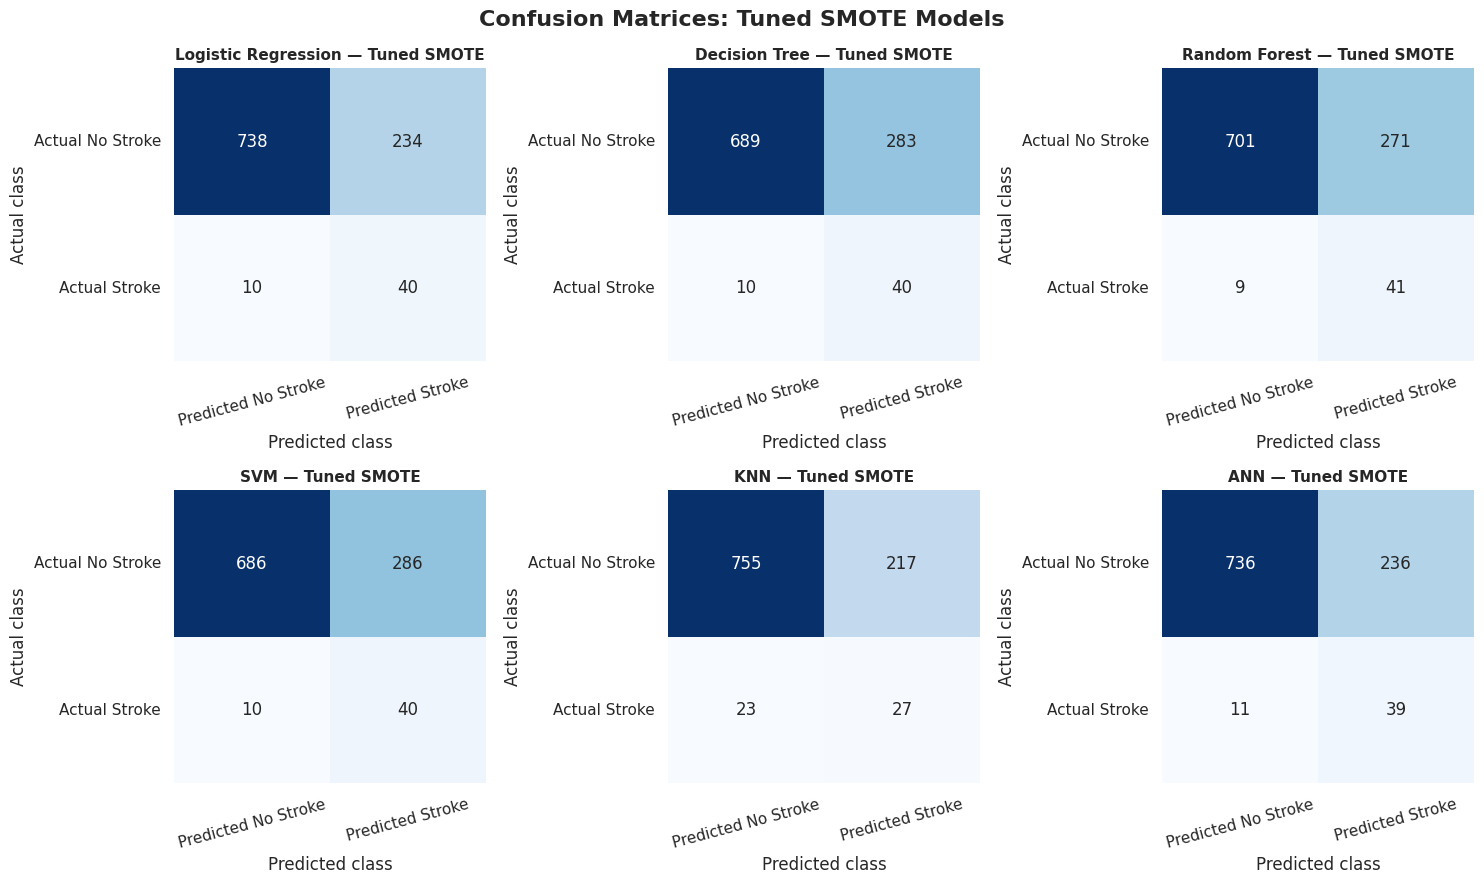

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, cm) in zip(axes.flatten(), smote_confusions.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicted No Stroke", "Predicted Stroke"],
        yticklabels=["Actual No Stroke", "Actual Stroke"]
    )
    ax.set_title(f"{name} — Tuned SMOTE", fontsize=11, weight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="x", rotation=15)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices: Tuned SMOTE Models", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

## 8. Final model ranking and interpretation

The ranking below uses test-set F1-score. It is a descriptive comparison, not a claim that the model is clinically suitable. Stroke prediction is a high-stakes medical task and these results are for an academic ML exercise only.

In [10]:
final_ranking = smote_df.sort_values(
    by=["F1-Score", "Recall"],
    ascending=False
).reset_index(drop=True)

print("Tuned SMOTE models ranked by test F1-score:")
display(final_ranking.round(4))

best_row = final_ranking.iloc[0]
print(
    f"\\nBest F1-score in this run: {best_row['Model']} "
    f"(F1={best_row['F1-Score']:.4f}, "
    f"Recall={best_row['Recall']:.4f}, "
    f"Precision={best_row['Precision']:.4f}, "
    f"Accuracy={best_row['Accuracy']:.4f})."
)

print("\\nInterpretation:")
print("- Recall measures the proportion of actual stroke cases detected.")
print("- Precision measures how many predicted stroke cases were truly stroke cases.")
print("- F1-score balances Precision and Recall.")
print("- Accuracy can decrease after SMOTE because the model predicts more minority-class cases.")
print("- Do not claim every metric improved if the measured results do not show that.")

Tuned SMOTE models ranked by test F1-score:


,Model,CV Best F1,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.2298,0.1460,0.80,0.2469,0.7613,0.8381
1,ANN,0.2211,0.1418,0.78,0.2400,0.7583,0.8365
2,Random Forest,0.2137,0.1314,0.82,0.2265,0.7260,0.8278
3,Decision Tree,0.2042,0.1238,0.80,0.2145,0.7133,0.7609
4,SVM,0.2189,0.1227,0.80,0.2128,0.7104,0.8398
5,KNN,0.1672,0.1107,0.54,0.1837,0.7652,0.7174


\nBest F1-score in this run: Logistic Regression (F1=0.2469, Recall=0.8000, Precision=0.1460, Accuracy=0.7613).
\nInterpretation:
- Recall measures the proportion of actual stroke cases detected.
- Precision measures how many predicted stroke cases were truly stroke cases.
- F1-score balances Precision and Recall.
- Accuracy can decrease after SMOTE because the model predicts more minority-class cases.
- Do not claim every metric improved if the measured results do not show that.
